# Nuages de mots

## Imports et stopwords

In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\asusz\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [3]:
# Choisir une année
year = 1963

In [4]:
# Lister les fichiers de cette année
data_path = '../data'
txt_path = '../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [5]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [6]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [7]:
# Imprimer tous les caractères du contenu de tous les fichiers
content_list[:]

['16 LE S OIR DIMANCHE 13 et LUNDI H JANVIER i963 Lil M son SAMOIS 114, RUE ROYALE à côté du journal * LE SOIR > BRUXELLES. Solde un choix exceptionnel de d\'origines diverses notamment : Hamadan - Mahal ■ Zarnim - Heriz Kirman - Caradja etc. ainsi qu\'un des stocks les plus importants du pays de Etnds dn notaire Pierre PISSOORT 9, me dn Pont-Neuf Bruxellei Tél. 17.55.28 La plupart de nos tapis de Tournai soldés avec remise de 15 à 40 % Notre qualité « VERSAILLES » Boucle - col gris et anthracite obtenable en largeur 0,60 - 0,70 - 3,66 et 4,57 m. sur longueur désirée à 350 Frs/m2 au lieu de. 440 Placement impeccable de tapis plains et d\'escaliers. Maison BELGE 223054 BROOKS, Auguste Mari», ses représentants ou ses enfants. Veuille^ prendre connaissance de réclamer contre la succession d’Erle Brooks pour ou avant le 13 avril 1933 sans quoi les autres membres de la famille se partageront la succession. M. A. SEERY, Public Trustée, 19 O’Connell St., SYDNEY, Australie. RESULTATS DES VENTE

In [8]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [9]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"16 LE S OIR DIMANCHE 13 et LUNDI H JANVIER i963 Lil M son SAMOIS 114, RUE ROYALE à côté du journal * LE SOIR > BRUXELLES. Solde un choix exceptionnel de d'origines diverses notamment : Hamadan - Mahal ■ Zarnim - Heriz Kirman - Caradja etc. ainsi qu'un des stocks les plus importants du pays de Etnds dn notaire Pierre PISSOORT 9, me dn Pont-Neuf Bruxellei Tél. 17.55.28 La plupart de nos tapis de Tournai soldés avec remise de 15 à 40 % Notre qualité « VERSAILLES » Boucle - col gris et anthracite ob"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [10]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [11]:
clean_text(year, folder=temp_path)

'Output has been written in ../data/tmp/1963_clean.txt!'

In [12]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'OIR DIMANCHE LUNDI JANVIER LIL SAMOIS RUE ROYALE CÔTÉ JOURNAL SOIR BRUXELLES SOLDE CHOIX EXCEPTIONNEL ORIGINES DIVERSES NOTAMMENT HAMADAN MAHAL ZARNIM HERIZ KIRMAN CARADJA ETC STOCKS IMPORTANTS PAYS ETNDS NOTAIRE PIERRE PISSOORT PONT NEUF BRUXELLEI TÉL PLUPART TAPIS TOURNAI SOLDÉS REMISE QUALITÉ VERSAILLES BOUCLE COL GRIS ANTHRACITE OBTENABLE LARGEUR LONGUEUR DÉSIRÉE FRS LIEU PLACEMENT IMPECCABLE TAPIS PLAINS ESCALIERS MAISON BELGE BROOKS AUGUSTE MARI REPRÉSENTANTS ENFANTS VEUILLE PRENDRE CONNAI'

## Nuage de mots

### Afficher les termes les plus fréquents


In [13]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 1493), ('BRUXELLES', 1279), ('TÉL', 1170), ('ANS', 681), ('PRIX', 604), ('TRÈS', 538), ('APP', 498), ('HEURES', 462), ('ECRIRE', 414), ('SOIR', 412)]


### Créer, stocker et afficher le nuage de mots

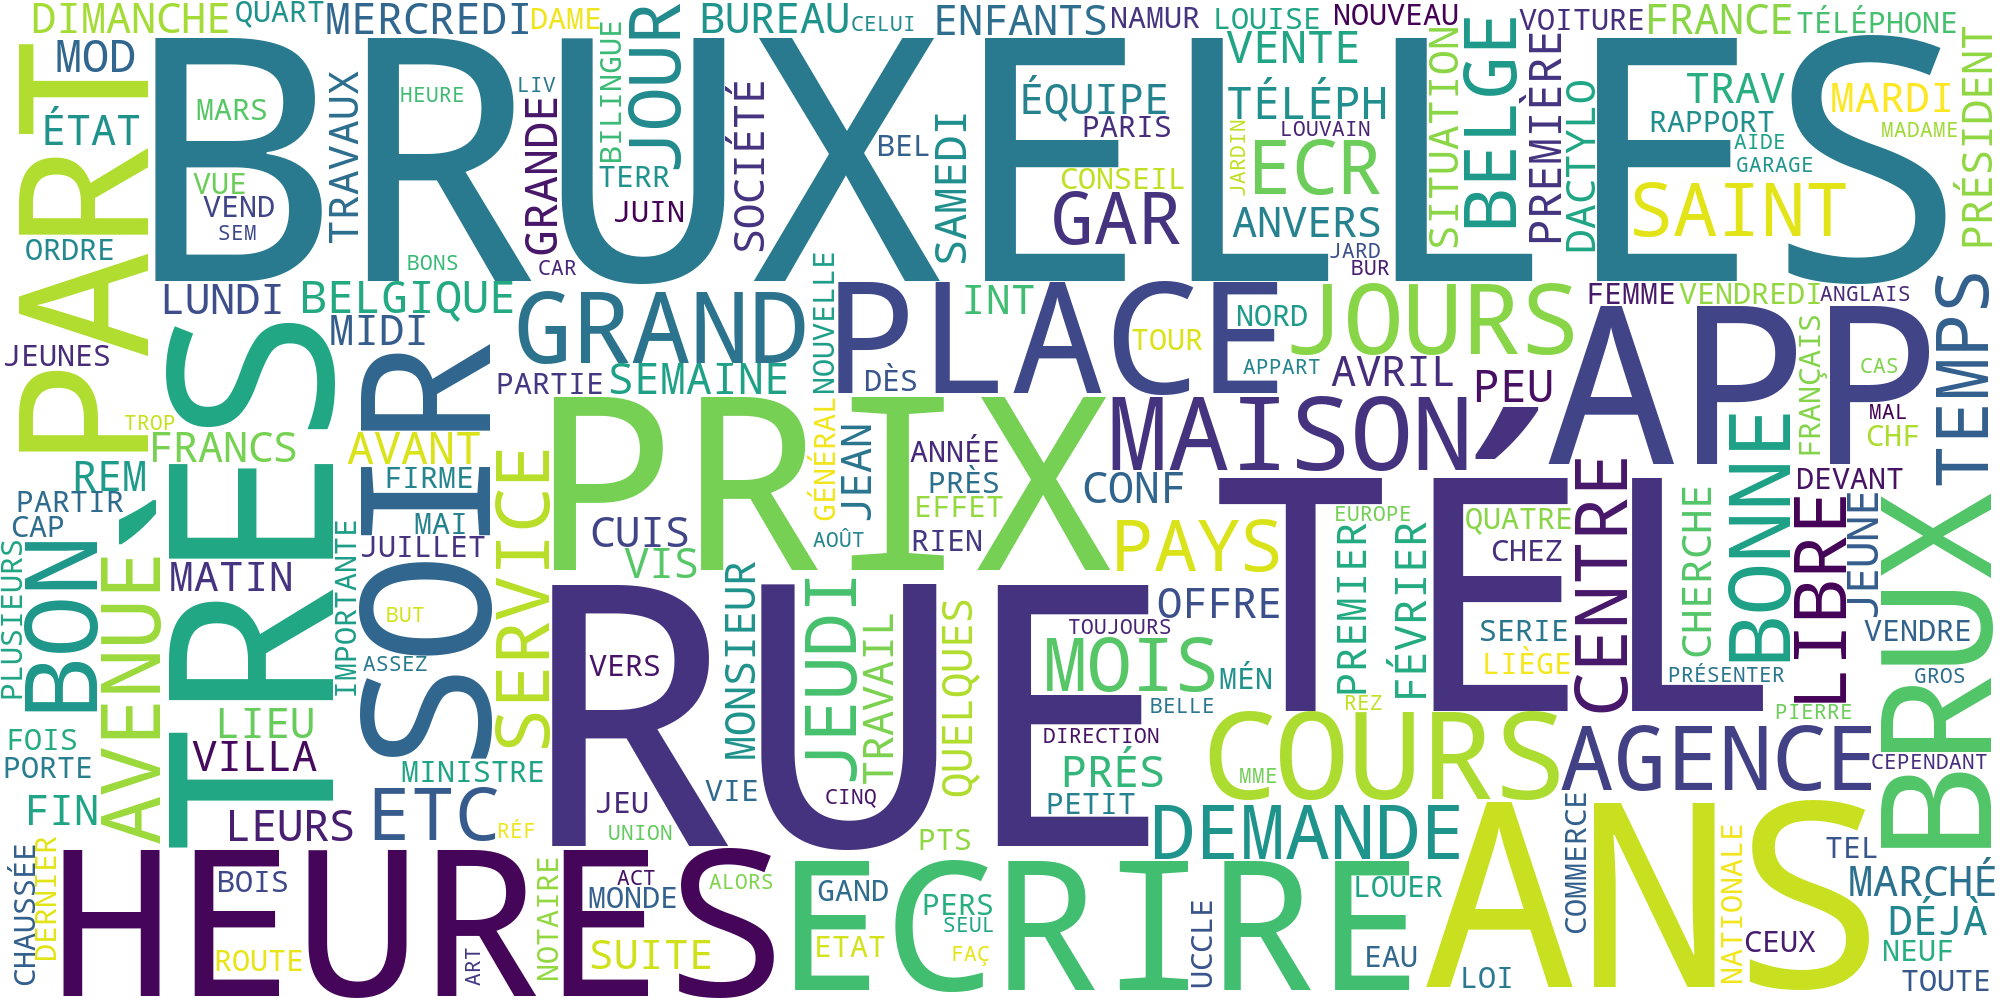

In [14]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))